# Getting started with `fastpiclef`

**Fast Picard–Lefschetz** wave-optics / Fresnel-integral solver.
It computes the amplification factor
$$F(\omega,\boldsymbol\beta) = \Big(\tfrac{\omega}{2\pi i}\Big)^{d/2}\int_{\mathbb R^d} e^{\,i\omega\phi(\mathbf x;\boldsymbol\beta)}\,d^d x,$$
normalised so free space gives $F=1$.

**Install (editable, from the repo):**
```bash
pixi run -e notebook build     # maturin develop --release into the notebook env
pixi run -e notebook lab       # launch JupyterLab
```

The wrapper exposes a *parametrised phase library* and a choice of solver method
(`mesh`, `thimble`, `polar`, `auto`) — not arbitrary Python phase callbacks, which
would forfeit the performance the Rust core is built for.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastpiclef as fpl
print('fastpiclef', [c for c in dir(fpl) if c[0].isupper()])

fastpiclef ['AiryPhase', 'CustomRationalLens', 'PointMassField', 'RationalLens', 'RationalLens2D', 'Result', 'SimGLens']


## 1. Trust anchor: the Airy integral

$\int_{\mathbb R} e^{\,i\omega(x^3/3 - yx)}\,dx = 2\pi\,\omega^{-1/3}\,\mathrm{Ai}(-\omega^{2/3}y)$ —
an exact closed form. The solver should hit it to machine precision, through the caustic ($y=0$) too.

In [2]:
from scipy.special import airy
print(f"{'y':>5}{'omega':>7}{'|integral|':>16}{'rel. err vs Ai':>18}")
for y in (-1.0, 0.0, 1.0):
    for omega in (1.0, 4.0):
        r = fpl.AiryPhase(y=y).solve(omega=omega)
        exact = 2*np.pi*omega**(-1/3)*airy(-(omega**(2/3))*y)[0]
        print(f'{y:5.1f}{omega:7.1f}{abs(r.integral):16.10f}{abs(r.integral-exact)/abs(exact):18.2e}')

    y  omega      |integral|    rel. err vs Ai
 -1.0    1.0    0.8500673223          6.40e-15
 -1.0    4.0    0.0602143816          8.16e-14
  0.0    1.0    2.2307070518          2.37e-12
  0.0    4.0    1.4052573854          1.63e-13
  1.0    1.0    3.3650282730          2.90e-15
  1.0    4.0    0.4976881587          7.05e-16


## 2. See the deformation: Lefschetz thimbles

The method replaces the wildly oscillating real-axis integral with an equivalent one along
*constant-phase contours* (thimbles) through the images, where the integrand decays instead of
oscillating. Here is a converging lens with three real images and a complex pair.

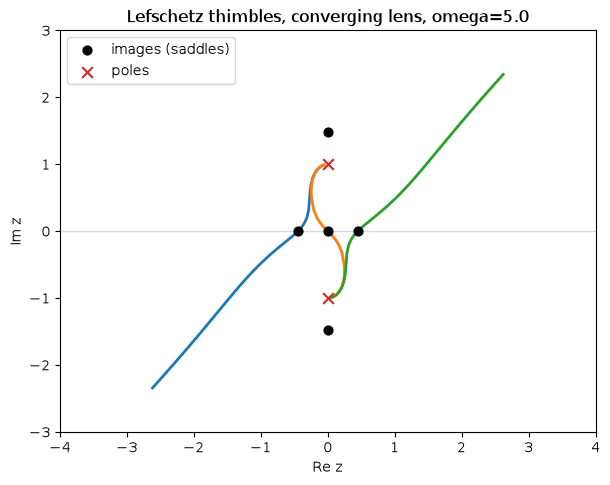

In [3]:
lens = fpl.RationalLens(beta=0.0, kappa=-0.72)   # phi = z^2/2 - kappa/(1+z^2)
omega = 5.0
pieces = lens.thimble(omega)
saddles = np.array(lens.saddles())
poles = np.array([1j, -1j])   # rational lens: psi = 1/(1+z^2)

fig, ax = plt.subplots(figsize=(6.2, 5))
ax.axhline(0, color='0.85', lw=1, zorder=0)
for p in pieces:
    p = np.array(p)
    ax.plot(p.real, p.imag, lw=2)
ax.scatter(saddles.real, saddles.imag, c='k', s=40, zorder=5, label='images (saddles)')
ax.scatter(poles.real, poles.imag, marker='x', c='C3', s=60, zorder=5, label='poles')
ax.set(xlabel='Re z', ylabel='Im z', title=f'Lefschetz thimbles, converging lens, omega={omega}')
ax.set_xlim(-4, 4); ax.set_ylim(-3, 3); ax.set_aspect('equal'); ax.legend()
plt.tight_layout(); plt.show()

## 3. The wave → geometric-optics transition

The magnification $|F|^2$ interpolates between smooth diffraction (small $\omega$, wave optics)
and the interference of the discrete geometric images (large $\omega$). The dashed line is the
geometric-optics total magnification $\sum_j |\mu_j| = \sum_j 1/|\phi''(x_j)|$ over the real
images: at small $\omega$ diffraction suppresses $|F|^2$ below it; at large $\omega$ the image
interference oscillates around it.

*(Very small $\omega$ needs a wider contour window — an automatic $\omega$-scaling is planned —
which is why the leftmost points are less reliable.)*

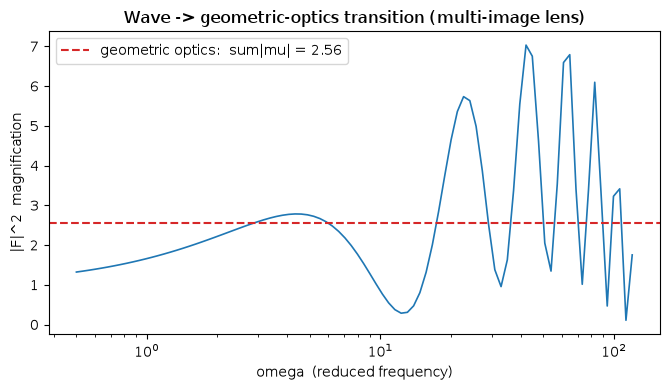

In [4]:
lens = fpl.RationalLens(beta=0.2, kappa=-1.2)
omegas = np.geomspace(0.5, 120.0, 90)
amps, _ = lens.sweep(list(omegas))
magn = np.abs(np.array(amps))**2

kappa = -1.2
d2phi = lambda x: 1.0 + 2*kappa*(1 - 3*x*x)/(1 + x*x)**3   # phi'' for this lens
images_1d = [z.real for z in lens.saddles() if abs(z.imag) < 1e-9]
mu_tot = sum(1.0/abs(d2phi(x)) for x in images_1d)

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.plot(omegas, magn, lw=1.2)
ax.axhline(mu_tot, ls='--', color='C3', label=f'geometric optics:  sum|mu| = {mu_tot:.2f}')
ax.set_xscale('log')
ax.set(xlabel='omega  (reduced frequency)', ylabel='|F|^2  magnification',
       title='Wave -> geometric-optics transition (multi-image lens)')
ax.legend(); plt.tight_layout(); plt.show()

## 4. Frontier: a field of 40 point-mass lenses

A random field of microlenses — the stellar-field problem. A few honest caveats:

* It is genuinely 2D and **not** axisymmetric, so the fast thimble path does not apply — this
  runs on the **general mesh-flow solver** (seconds per evaluation, not milliseconds).
* Point masses carry logarithmic singularities, the known hard case; the result below is
  **convergence-demonstrated, not yet benchmark-validated** (a single-mass Nakamura–Deguchi
  check is planned). The reported error bar is honest.

This is the current frontier of what the general solver handles out of the box.

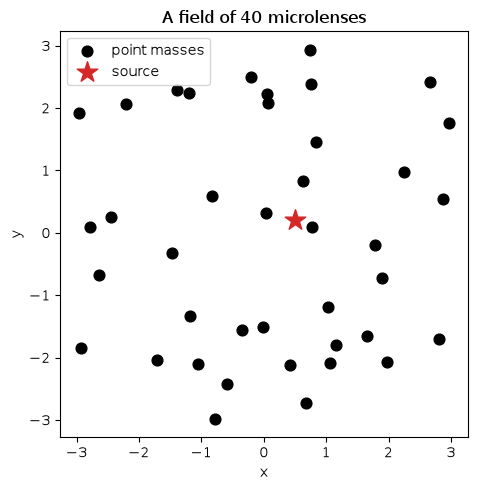

In [5]:
rng = np.random.default_rng(7)
pos = rng.uniform(-3.0, 3.0, size=(40, 2))
masses = np.full(40, 0.05)
lenses = [(float(x), float(y), float(m)) for (x, y), m in zip(pos, masses)]
beta = (0.5, 0.2)
field = fpl.PointMassField(lenses, beta=beta)

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(pos[:, 0], pos[:, 1], s=60, c='k', label='point masses')
ax.scatter([beta[0]], [beta[1]], marker='*', s=240, c='C3', zorder=5, label='source')
ax.set(xlabel='x', ylabel='y', title='A field of 40 microlenses'); ax.set_aspect('equal'); ax.legend()
plt.tight_layout(); plt.show()

In [6]:
# One amplification evaluation on the general 2D mesh solver (~20-40 s, coarse).
r = field.solve(omega=2.0, delta=0.05, domain=(-6.0, 6.0))
print(r)
print(f'|F| = {abs(r.amplification):.4f}   |F|^2 = {abs(r.amplification)**2:.4f}   method = {r.method}')

Result(amplification=-1.219852+0.248860i, integral=-0.781817-3.832279i, error=1.33e-1, method='mesh', steps=60)
|F| = 1.2450   |F|^2 = 1.5500   method = mesh


## 5. The lensed image: from points to a field

For a point source, **geometric optics** predicts a set of *discrete images* — the solutions of
the lens equation $\boldsymbol\beta = \mathbf x - \nabla\psi(\mathbf x)$ (equivalently the real
stationary points of $\phi$). Toward the **wave-optics** regime each image is smeared over the
**Fresnel scale $\sim\omega^{-1/2}$**; near caustics the blurred images overlap into extended
structure — a *field* rather than points.

Below: the exact geometric images (left), then the same images broadened by the Fresnel scale at
two frequencies. The geometric images come from the lens equation; the broadening is the leading
Fresnel-scale picture, complementary to the full diffraction integral $|F|$ of section 4 — whose
$|F|^2$ at moderate $\omega$ sits near the geometric total magnification $\sum_j|\mu_j|$ printed below.

12 geometric images;  total |mu| (geometric magnification) = 1.491


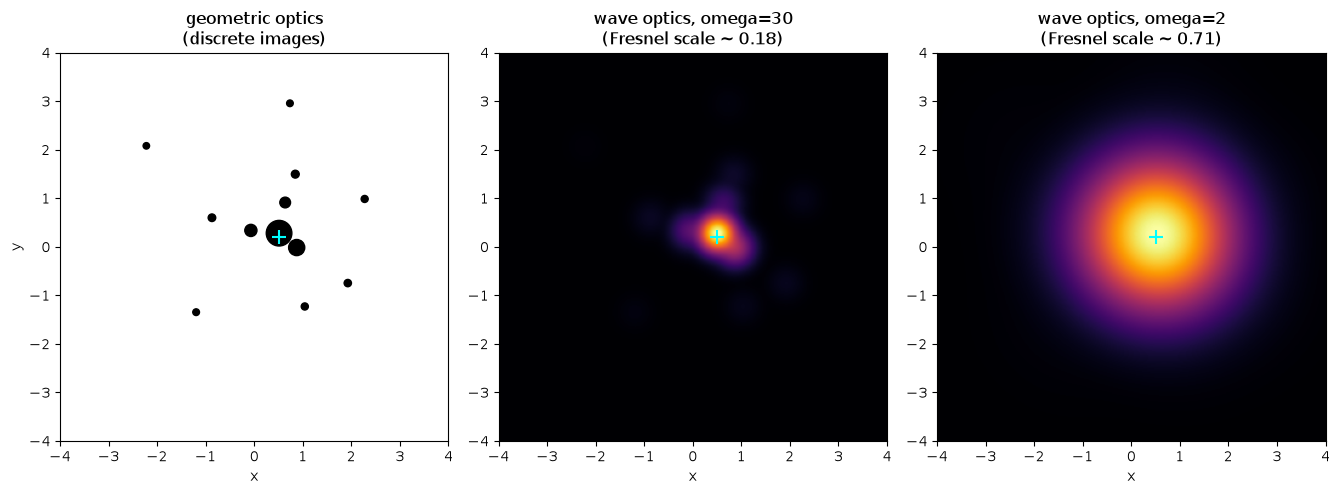

In [7]:
# Geometric images of the field: real solutions of grad(phi) = 0, by multi-start Newton.
b = np.array(beta)
def _grad(x):
    d = x - pos; r2 = (d**2).sum(1)
    return (x - b) - (masses[:, None]*d/r2[:, None]).sum(0)
def _hess(x):
    d = x - pos; r2 = (d**2).sum(1); H = np.eye(2)
    for k in range(len(pos)):
        H -= masses[k]*(np.eye(2)/r2[k] - 2*np.outer(d[k], d[k])/r2[k]**2)
    return H

seeds = np.array(np.meshgrid(np.linspace(-4, 4, 55), np.linspace(-4, 4, 55))).reshape(2, -1).T
imgs = []
for s in seeds:
    x = s.copy()
    for _ in range(60):
        g = _grad(x)
        if np.linalg.norm(g) < 1e-10: break
        try: x = x - np.linalg.solve(_hess(x), g)
        except np.linalg.LinAlgError: break
        if np.linalg.norm(x) > 8: break
    if np.linalg.norm(_grad(x)) < 1e-8 and np.linalg.norm(x) < 8:
        if not any(np.linalg.norm(x - i) < 1e-3 for i in imgs): imgs.append(x)
imgs = np.array(imgs)
mu = np.array([1.0/abs(np.linalg.det(_hess(x))) for x in imgs])
print(f'{len(imgs)} geometric images;  total |mu| (geometric magnification) = {mu.sum():.3f}')

gx = np.linspace(-4, 4, 320); X, Y = np.meshgrid(gx, gx)
def intensity(sigma):
    I = np.zeros_like(X)
    for (ix, iy), m in zip(imgs, mu):
        I += m*np.exp(-((X - ix)**2 + (Y - iy)**2)/(2*sigma**2))
    return I

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
axes[0].scatter(imgs[:, 0], imgs[:, 1], s=20 + 320*np.sqrt(mu/mu.max()), c='k')
axes[0].set_title('geometric optics\n(discrete images)')
for ax, w in zip(axes[1:], (30.0, 2.0)):
    sig = 1.0/np.sqrt(w)
    ax.imshow(intensity(sig)**0.4, extent=[-4, 4, -4, 4], origin='lower', cmap='inferno')
    ax.set_title(f'wave optics, omega={w:g}\n(Fresnel scale ~ {sig:.2f})')
for ax in axes:
    ax.scatter([b[0]], [b[1]], marker='+', c='cyan', s=90, zorder=6)
    ax.set_aspect('equal'); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_xlabel('x')
axes[0].set_ylabel('y')
plt.tight_layout(); plt.show()

## What's next

* An automated comparison harness against `plind` / `P-LPI` / `fiona` (speed & convergence).
* The point-mass lens with its Nakamura–Deguchi closed form as an external benchmark.
* $\omega$-aware auto-configuration, so sweeps need no manual window tuning.
* A true wave-optics magnification map $|F(\omega,\boldsymbol\beta)|^2$ over source position
  (a direct solver output, once per-point cost is reduced).

See the project journal for the full roadmap.